In [217]:
import math

import numpy as np
import qiskit

import bosonic_qiskit
from qiskit.circuit import Parameter
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)

# Simulation of the Jaynes-Cummings Hamiltonian on a spin-boson hardware

The Hamiltonian is
$H=\omega_C a^\dagger a + \frac{\omega_A}{2}\sigma_z + \lambda \sigma_x (a^\dagger + a)$
</br></br>
We simulate the trotterized time evolution under this Hamiltonian  by implementing each term in $U_L=e^{-i \omega_C a^\dagger a t}$, $U_M=e^{-i \omega_A \sigma^z t/2}$ and $U_{LM}=e^{-i \lambda \sigma^z (a^\dagger + a) t}$ individually.

In [214]:
def eiht(circuit, boson, spin, omega_A, omega_C, lam, dt):
    # Appending each gate to the circuit
    
    # U_L = exp(-i omega_C a^\dag a t): rotation for the boson
    circuit.cv_r(-omega_C*dt,boson[0])

    # U_M = exp(-i omega_A \sigma_z/2 t): rotation for the spin
    circuit.rz(omega_A*dt,spin[0])

    # Implementing U_LM = exp(-i lambda \sigma_z (a^\dag +a) t) for the spin and the boson
    
    # Note that the controlled displacement gate uses sigma_z for the spin, not sigma_x, so we
    # rotate the spin's X component into Z 
    circuit.ry(-math.pi/2,spin[0])

    # U_LM' = exp(-i lambda \sigma_z (a^\dag +a) t), as controlled displacement for the spin and the boson
    circuit.cv_c_d(-1j*lam*dt,boson[0],spin[0])

    # Rotate back the spin's Z component into X
    circuit.ry(math.pi/2,spin[0])

    return circuit

def trotterise(circuit, boson, spin, omega_A, omega_C, lam, N, dt, circuit_list):
    # Buling a series of circuits of length n time steps for n = 0 to N-1.
    # Returns: list of circuits 
    
    # Trotterised time evolution
    for i in range(N):
        # Implement the circuit, add gates for time evolution 
        eiht(circuit, boson, spin, omega_A, omega_C, lam, dt)
        circuit_list = circuit_list + [circuit.copy()]
        
    return circuit_list

def estimate(circuit, observable, params, estimator):
    # Computing observables with the Estimator functionality
    
    # The circuit needs to be transpiled to the AerSimulator target
    pass_manager = generate_preset_pass_manager(1, AerSimulator())
    isa_circuit = pass_manager.run(circuit)
    pub = (isa_circuit, observable, params)
    
    job = estimator.run([pub])
    result = job.result()
    pub_result = result[0]
    value = float(pub_result.data.evs)
    
    return value 

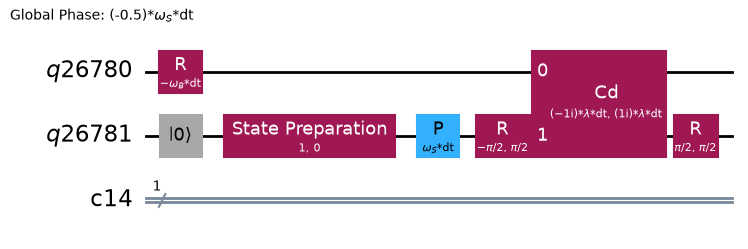

In [163]:
from qiskit.circuit import Parameter
# Cutoff of the qumode's Fock space: 2^num_qubits_per_qumode
num_qubits_per_qumode = 1

# Create new circuit
boson = bosonic_qiskit.QumodeRegister(num_qumodes=1, num_qubits_per_qumode=num_qubits_per_qumode)
spin = qiskit.QuantumRegister(1)
classbit = qiskit.ClassicalRegister(1)
circuit = bosonic_qiskit.CVCircuit(boson,spin,classbit)

# Initialize state to the upper state of the spin
circuit.initialize([1, 0], spin)

omega_A = Parameter('$\omega_S$')
omega_C = Parameter('$\omega_B$')
lam = Parameter('$\lambda$')
dt = Parameter('dt')
circuit_print = circuit.copy()
eiht(circuit_print, boson, spin, omega_A, omega_C, lam, dt)
circuit_print.decompose().draw(output='mpl')


In [164]:
# Define Hamiltonian parameters
omega_A = 1
omega_C = 1
lam = 0.1

# Define computational parameters 
t_tot = 2*np.pi/lam # total time 
N = 50 # number of Trotter time steps
dt = t_tot/N # timestep

# Define matrices of the observables
I_qumode = circuit.ops.get_eye(boson.cutoff).toarray()
sigmax = np.kron(np.array([[0, 1], [1, 0]]), I_qumode) # sigma_x of the spin
sigmaz = np.kron(np.array([[1, 0], [0, -1]]), I_qumode) # sigma_z of the spin

In [215]:
# Build list of circuits for the points in teh time series
circuit_list = []
circuit_list = trotterise(circuit, boson, spin, omega_A, omega_C, lam, N, dt, circuit_list)

In [216]:
# Calculating expectation values according to the original tutorial
sigma_x_expectation = []
sigma_z_expectation = []

for i, c in enumerate(circuit_list):
    if i%10==0:
        print("step", i)

    # Run cirtuit -- starting from the initial state!!!  
    state, result, fock_counts = bosonic_qiskit.util.simulate(c)

    sigma_x_expectation.append(state.expectation_value(sigmax).real)
    sigma_z_expectation.append(state.expectation_value(sigmaz).real)

step 0
step 10
step 20
step 30
step 40


In [218]:
# Estimating observables
params = [] # circuit parameters
# Converting sigmaz matrix to Pauli strings
observable = SparsePauliOp.from_operator(sigmaz)
print(observable)

SparsePauliOp(['ZI'],
              coeffs=[1.+0.j])


In [219]:
#Estimating observables with Exact estimator
exact_estimator = Estimator()
sigma_z_expectation_exact = []

for i, c in enumerate(circuit_list):
    if i%10==0:
        print("step", i)
    value = estimate(c, observable, params, exact_estimator)
    sigma_z_expectation_exact.append(value)

step 0
step 10
step 20
step 30
step 40


In [241]:
#Estimating observables with Noisy estimator

sigma_z_expectation_noisy_list = []
p_error = [0.001, 0.005, 0.01]

for p in p_error:
    noise_model = NoiseModel()
    bit_flip = pauli_error([("X", p), ("I", 1 - p)])
    #phase_flip = pauli_error([("Z", p_error), ("I", 1 - p_error)])
    print(bit_flip)
    #print(phase_flip)
    noise_model.add_all_qubit_quantum_error(bit_flip, ['u1', 'u2', 'u3'])

    noisy_estimator = Estimator(
        options=dict(backend_options=dict(noise_model=noise_model))
    )

    sigma_z_expectation_noisy = []

    for i, c in enumerate(circuit_list):
        if i%10==0:
            print("step", i)
        value = estimate(c, observable, params, noisy_estimator)
        sigma_z_expectation_noisy.append(value)
    sigma_z_expectation_noisy_list.append(sigma_z_expectation_noisy) 

QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.001, Circuit = 
   ┌───┐
q: ┤ X ├
   └───┘
  P(1) = 0.999, Circuit = 
   ┌───┐
q: ┤ I ├
   └───┘
step 0
step 10
step 20
step 30
step 40
QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.005, Circuit = 
   ┌───┐
q: ┤ X ├
   └───┘
  P(1) = 0.995, Circuit = 
   ┌───┐
q: ┤ I ├
   └───┘
step 0
step 10
step 20
step 30
step 40
QuantumError on 1 qubits. Noise circuits:
  P(0) = 0.01, Circuit = 
   ┌───┐
q: ┤ X ├
   └───┘
  P(1) = 0.99, Circuit = 
   ┌───┐
q: ┤ I ├
   └───┘
step 0
step 10
step 20
step 30
step 40


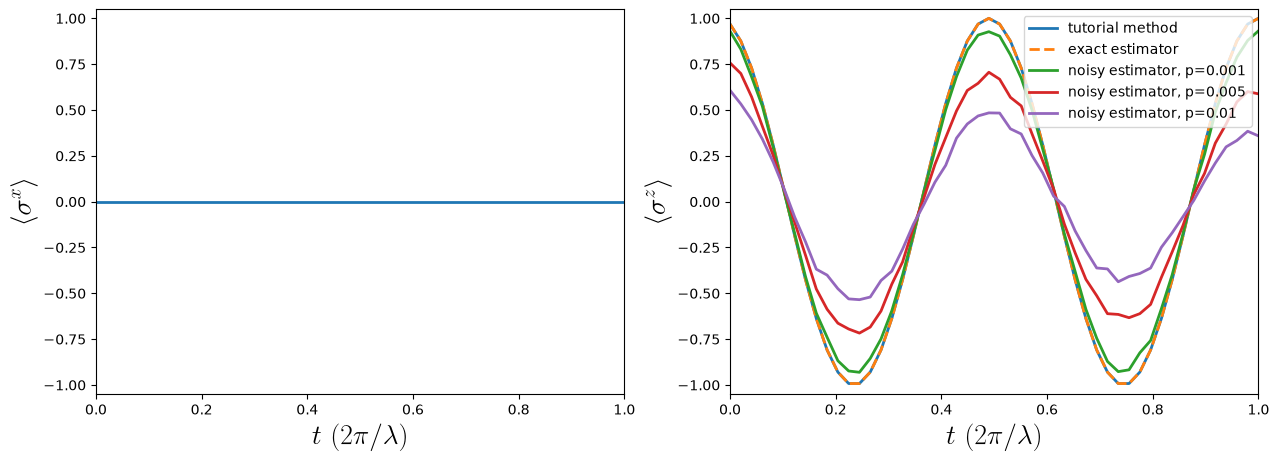

In [242]:
import matplotlib.pyplot as plt

fontsize = 20

tarray = np.linspace(0,t_tot,N)

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(tarray/(2*np.pi/lam),sigma_x_expectation,linewidth=2)
plt.ylabel(r'$\langle\sigma^x\rangle$',fontsize=fontsize,usetex=True);
plt.xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);
plt.xlim([0,1]);
plt.ylim([-1.05,1.05]);

plt.subplot(1,2,2)
plt.plot(tarray/(2*np.pi/lam),sigma_z_expectation,linewidth=2,label="tutorial method")
plt.plot(tarray/(2*np.pi/lam),sigma_z_expectation_exact,linewidth=2,linestyle='dashed', label="exact estimator")
for i, p  in enumerate(p_error):
    plt.plot(tarray/(2*np.pi/lam),sigma_z_expectation_noisy_list[i],linewidth=2,label=f"noisy estimator, p={p}")
plt.ylabel(r'$\langle\sigma^z\rangle$',fontsize=fontsize,usetex=True);
plt.xlabel(r'$t$ $(2\pi/\lambda)$',fontsize=fontsize,usetex=True);
plt.legend(loc='upper right')
plt.xlim([0,1]);
plt.ylim([-1.05,1.05]);

In [228]:
p_error

[0.001, 0.01, 0.01]